# Prognooside ja veaparandajate võrdlus
Vali projekti **.venv** kernel ning käivita **Restart Kernel → Run All**. Kogu analüüs toimub siin: andmed → baasmudelite võrdlus → OOF-treening → arendusvalikud → lõpphindamine → tabelid ja graafikud. Eraldi tulemuse- ega aruandefaile ei looda.

Põhivõrdlus on lihtne sama kellaaja veaparandus versus SHAP-krediidiga parandaja. Lisakontrollid näitavad baasprognoosi, parandusmudeli, krediidireegli, kellaaja ja mälu panust.

Panama 2020 ja Eesti 2024 on varem uuritud perioodid: see on tagasivaateline võrdlus. Seaded valitakse Panama 2018–2019 arenduses ning kantakse Eestisse muutmata.

In [1]:
from pathlib import Path
from copy import deepcopy
import sys

sys.dont_write_bytecode = True
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/experiment.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

from src.common import read_config
from src.data_preprocessing import load_and_audit, validate_for_modeling
from src.feature_engineering import (
    ERROR_FEATURES, build_features, feature_columns, known_error_features,
    load_dataset, split_year,
)
from src.models import residual_forecasts
from src.study import annual_forecast, oof_history, develop, policy_forecasts, validate_config
from src.compare_forecasting_models import compare_models
from src.evaluation import clock_loss_interval, scope_masks, score_forecasts

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.4f}".format

C:\Users\danyi\Desktop\TALTECH magister\Magistritöö\xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
cfg = read_config()  # Olemasolev configs/experiment.json; notebook ei muuda seda.
validate_config(cfg)
DATASETS = ("panama", "estonia")
METHODS = ("base", "residual", "hourly_bias", "credit_feedback")
LABELS = {"base": "Baas", "residual": "Jääkparandus",
          "hourly_bias": "Lihtne", "credit_feedback": "XAI"}
BASELINES = ("base", "direct", "residual", "fixed", "scalar_adaptive",
             "standalone_feedback", "hourly_bias", "credit_feedback")
LABELS.update({"direct": "Otseprognoos", "fixed": "Püsikaal",
               "scalar_adaptive": "Üks adaptiivne kaal",
               "standalone_feedback": "Osad eraldi",
               "matched_scalar": "Üks krediidikaal",
               "matched_standalone": "Koosmõjuta", "no_context": "Kellaajata"})
COLORS = {"base": "#8b95a5", "residual": "#4c78a8",
          "hourly_bias": "#e58b2a", "credit_feedback": "#21918c"}
COUNTRIES = {"panama": "Panama", "estonia": "Eesti"}
EXAMPLE_OFFSET_DAYS = 7  # Ajagraafiku algus: seitse päeva pärast hindamise algust.
EXAMPLE_DAYS = 3

display(pd.DataFrame([
    {"Andmestik": COUNTRIES[d], "Arendusaastad": str(cfg["datasets"][d]["development_years"]),
     "Hindamisaasta": cfg["datasets"][d]["test_year"]}
    for d in DATASETS
]))
print("Baasmudel:", cfg["base_model_family"], "| parandusmudel: HistGBR")
print("Külmkäivitus:", cfg["feedback"]["warmup_hours"], "h; vajalik ajalugu:",
      cfg["feedback"]["min_history_points"], "sama rühma vaatlust.")

,Andmestik,Arendusaastad,Hindamisaasta
0,Panama,"[2018, 2019]",2020
1,Eesti,[],2024


Baasmudel: histgbr | parandusmudel: HistGBR
Külmkäivitus: 72 h; vajalik ajalugu: 3 sama rühma vaatlust.


## 1. Andmed ja tunnused
Arenduse tunnused ehitatakse enne 2020. aastat lõppevatest Panama andmetest. Kiire tõusu/languse piirid ja allolevad andmegraafikud kasutavad ainult arendusele eelnevat aega; olukorrasilt pole mudeli sisend.

In [3]:
panama_options = cfg["datasets"]["panama"]
raw, quality = load_and_audit(ROOT / panama_options["path"])
validate_for_modeling(raw, quality)
development_raw = raw[raw.datetime < f"{panama_options['test_year']}-01-01"].copy()
panama_development = build_features(development_raw, cfg, "panama")
base_columns, correction_columns = feature_columns("panama")
initial = panama_development[
    panama_development.target_time < panama_options["threshold_end"]
]
panama_thresholds = {
    "increase": float(initial.actual_ramp.quantile(0.95)),
    "decrease": float(initial.actual_ramp.quantile(0.05)),
}


training_view = panama_development[
    panama_development.target_time < panama_options["threshold_end"]
].set_index("target_time")
display(training_view.target_next_hour.describe().to_frame("Arenduseelne koormus"))
print("Allika ridu:", quality["rows"], "| duplikaate:", quality["duplicate_timestamps"])

,Arenduseelne koormus
count,26087.0000
mean,1157.4774
std,192.3341
min,380.5936
25%,988.0887
50%,1142.5430
75%,1302.7778
max,1645.4773


Allika ridu: 48048 | duplikaate: 0


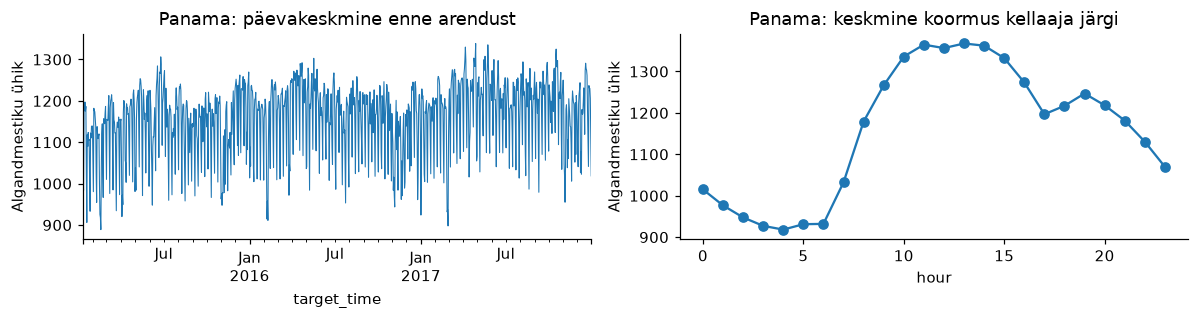

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
training_view.target_next_hour.resample("D").mean().plot(ax=axes[0], linewidth=0.7)
axes[0].set_title("Panama: päevakeskmine enne arendust")
training_view.groupby("hour").target_next_hour.mean().plot(ax=axes[1], marker="o")
axes[1].set_title("Panama: keskmine koormus kellaaja järgi")
for ax in axes:
    ax.set_ylabel("Algandmestiku ühik")
fig.tight_layout()
plt.show()

## 2. Baasmudelite arendusvõrdlus
Ridge, Random Forest, GBR ja HistGBR kasutavad samu tunnuseid, ridu ja treeningus sobitatud teisendust. Igal perekonnal on üks fikseeritud seadistus. Tabel põhjendab baasivalikut uuritud variantide hulgas; konfiguratsioonis määratud baasi automaatselt ei muudeta.

In [5]:
preliminary, preliminary_folds, preliminary_boundaries = compare_models(panama_development, cfg)
display(preliminary[["model", "n", *[f"MAE_{year}" for year in panama_options["development_years"]], "MAE", "RMSE", "bias"]])
print("Parim arenduse MAE:", preliminary.iloc[0].model)
print("Põhivõrdluse fikseeritud baasmudel:", cfg["base_model_family"])

Development 2018: Ridge


Development 2018: RandomForest


Development 2018: GBR


Development 2018: HistGBR


Development 2019: Ridge


Development 2019: RandomForest


Development 2019: GBR


Development 2019: HistGBR


,model,n,MAE_2018,MAE_2019,MAE,RMSE,bias
0,HistGBR,17520,13.8817,19.3317,16.6067,25.6586,-1.4890
1,RandomForest,17520,15.0092,22.2582,18.6337,29.6843,-1.7600
2,GBR,17520,17.9250,24.5936,21.2593,30.8325,-2.4997
3,Ridge,17520,29.2048,30.8666,30.0357,39.8541,3.2776


Parim arenduse MAE: HistGBR
Põhivõrdluse fikseeritud baasmudel: histgbr


## 3. Ajapõhised OOF-prognoosid
Iga aasta baasprognoos tuleb ainult varasematel aastatel treenitud mudelist. Parandusmudel õpib nende ette tehtud prognooside vigadest.

In [6]:
with threadpool_limits(limits=cfg["workers"]):
    panama_history = oof_history(
        panama_development, panama_options["test_year"], base_columns, cfg
    )
display(panama_history.groupby(panama_history.target_time.dt.year).size().to_frame("OOF tunde"))

  Base OOF 2016: 8784 forecasts


  Base OOF 2017: 8760 forecasts


  Base OOF 2018: 8760 forecasts


  Base OOF 2019: 8760 forecasts


,OOF tunde
target_time,
2016,8784
2017,8760
2018,8760
2019,8760


## 4. Parandajate arendusvalik
Lihtne meetod lisab jäägiparandusele varasema sama kellaaja keskmise vea. XAI-meetod kaalub SHAP-komponente nende varasema krediidi järgi. Mõlemale valitakse aken ja tugevus ainult Panama 2018–2019 tulemustest.

Sama valikureegel hindab aastate ja olukordade MAE-suhtarve ning piirab halvenemist. Lisatud on fikseeritud kaal, üks adaptiivne kaal, lihtsam komponentide krediit ja mälu vananemise kontroll. Identiteet tähendab muutmata jäägiparandust.

In [7]:
with threadpool_limits(limits=cfg["workers"]):
    development_results, choices, decay = develop(
        panama_history, correction_columns, panama_thresholds, cfg
    )
selection = {"choices": deepcopy(choices), "decay": deepcopy(decay)}
choice_rows = []
for method, choice in choices.items():
    setting = choice["setting"] or {}
    choice_rows.append({
        "Meetod": LABELS[method], "Kandidaat": choice["candidate"],
        "Aken (h)": setting.get("window_hours"), "Tugevus": setting.get("strength"),
        "Sama kellaaeg": setting.get("by_hour", True),
        "Arenduse MAE-suhtarv": choice["development_ratio"],
    })
display(pd.DataFrame(choice_rows))
print("Mälu kontrollvariandi arendusvalik:", decay)
print("Kõik valikud on fikseeritud enne lõpphindamist.")

  Development 2018: evaluated fixed and adaptive policies


  Development 2019: evaluated fixed and adaptive policies


,Meetod,Kandidaat,Aken (h),Tugevus,Sama kellaaeg,Arenduse MAE-suhtarv
0,Püsikaal,identity,NaN,NaN,True,1.0000
1,Lihtne,hourly_bias_w168_s0.25,168.0000,0.2500,True,0.9887
2,Üks adaptiivne kaal,scalar_adaptive_w168_h1_s0.25,168.0000,0.2500,True,0.9975
3,Osad eraldi,standalone_feedback_w168_h1_s1.0,168.0000,1.0000,True,0.9948
4,XAI,credit_feedback_w168_h1_s1.0,168.0000,1.0000,True,0.9925


Mälu kontrollvariandi arendusvalik: {'candidate': 'decay_168', 'half_life_hours': 168, 'development_ratio': 0.9920089907648113, 'memory': 'exponential'}
Kõik valikud on fikseeritud enne lõpphindamist.


## 5. Lõppmudelite treening
Iga riigi mudelid treenitakse selle varasematel andmetel; Eesti saab Panama parandajate seaded. Kõik meetodid jagavad samu mudeleid ja hindamistunde. Aasta jooksul muutub tagasiside, mitte mudelite parameetrid.

Panama allikas lõpeb juunis. Puuduvad tunnid jäävad hindamata. Eesti ajatelg ja jaotused on UTC-s, kellaajarühmad Tallinna kohalikus ajas.

In [8]:
runs, metric_parts, coverage = {}, [], []
with threadpool_limits(limits=cfg["workers"]):
    for dataset in DATASETS:
        options = cfg["datasets"][dataset]
        frame, quality = load_dataset(ROOT / options["path"], cfg, dataset)
        base_columns, correction_columns = feature_columns(dataset)
        history = (panama_history if dataset == "panama" else
                   oof_history(frame, options["test_year"], base_columns, cfg))
        hold = annual_forecast(frame, options["test_year"], base_columns, cfg)
        combined = pd.concat(
            [history.drop(columns=ERROR_FEATURES), hold], ignore_index=True
        )
        combined = pd.concat([combined, known_error_features(combined)], axis=1)
        train, valid = split_year(combined, options["test_year"])
        fitted_forecasts, components, _ = residual_forecasts(
            train, valid, correction_columns, cfg
        )
        forecasts, traces = policy_forecasts(
            valid, fitted_forecasts, components, selection, cfg
        )
        weights = traces["credit_feedback"]
        effective = components * weights
        initial = frame[frame.target_time < options["threshold_end"]]
        thresholds = {"increase": float(initial.actual_ramp.quantile(0.95)),
                      "decrease": float(initial.actual_ramp.quantile(0.05))}
        assert train.target_time.max() <= valid.origin_time.min()
        assert valid.target_time.is_unique
        assert np.isfinite(np.column_stack(list(forecasts.values()))).all()
        runs[dataset] = {"frame": valid, "forecasts": forecasts, "weights": weights,
                         "components": components, "effective": effective,
                         "thresholds": thresholds}
        metric_parts.append(score_forecasts(
            valid, forecasts, thresholds, cfg, "final"
        ).assign(dataset=dataset))
        coverage.append({
            "Andmestik": COUNTRIES[dataset], "Esimene sihttund": valid.target_time.min(),
            "Viimane sihttund": valid.target_time.max(), "Hinnatud tunde": len(valid),
            "Aasta kalendritunde": quality["calendar_test_hours"],
            "Hindamata tunde": quality["unscored_test_hours"],
            "Viimane treeningu sihtaeg": train.target_time.max(),
        })

assert choices == selection["choices"]
metrics = pd.concat(metric_parts, ignore_index=True)
display(pd.DataFrame(coverage))

  Base OOF 2020: 4273 forecasts


  Base OOF 2019: 8708 forecasts


  Base OOF 2020: 8784 forecasts


  Base OOF 2021: 8760 forecasts


  Base OOF 2022: 8760 forecasts


  Base OOF 2023: 8708 forecasts


  Base OOF 2024: 8654 forecasts


,Andmestik,Esimene sihttund,Viimane sihttund,Hinnatud tunde,Aasta kalendritunde,Hindamata tunde,Viimane treeningu sihtaeg
0,Panama,2020-01-01,2020-06-27 00:00:00,4273,8784,4511,2019-12-31 23:00:00
1,Eesti,2024-01-01,2024-12-31 23:00:00,8654,8784,130,2023-12-31 23:00:00


## 6. Üldine täpsus ja peamised võrdlused
MAE on keskmine absoluutviga; RMSE rõhutab suuri vigu; bias näitab keskmist üle-/alaprognoosi. Väiksem MAE/RMSE on parem. Arvud on iga andmestiku oma ühikutes. Fikseeritud kaalu identiteet võib korrata standardparanduse tulemust.

In [9]:
overall = metrics[metrics.scope.eq("overall")].copy()
assert overall.groupby("dataset").n.nunique().eq(1).all()
overall_view = overall[overall.method.isin(BASELINES)].assign(
    Andmestik=overall.dataset.map(COUNTRIES), Meetod=overall.method.map(LABELS)
)[["Andmestik", "Meetod", "n", "MAE", "RMSE", "bias", "improvement_vs_residual_pct"]]
display(overall_view.rename(columns={
    "n": "Tunde", "bias": "Keskmine nihe",
    "improvement_vs_residual_pct": "Paranemine jäägiparandusest (%)",
}))

,Andmestik,Meetod,Tunde,MAE,RMSE,Keskmine nihe,Paranemine jäägiparandusest (%)
0,Panama,Baas,4273,20.4511,27.1860,-0.3301,-22.8250
3,Panama,Otseprognoos,4273,17.6173,23.6014,-0.0696,-5.8056
6,Panama,Jääkparandus,4273,16.6506,22.2651,0.9595,0.0000
9,Panama,Lihtne,4273,15.7702,21.1909,0.7312,5.2875
12,Panama,Püsikaal,4273,16.6506,22.2651,0.9595,0.0000
15,Panama,Üks adaptiivne kaal,4273,16.6227,22.2090,0.8420,0.1678
18,Panama,Osad eraldi,4273,15.7654,21.2128,0.3342,5.3165
21,Panama,XAI,4273,15.7765,21.2161,0.2676,5.2498
66,Eesti,Baas,8654,22.1208,31.5539,2.4164,-33.3376
69,Eesti,Otseprognoos,8654,16.6979,24.3231,1.6792,-0.6499


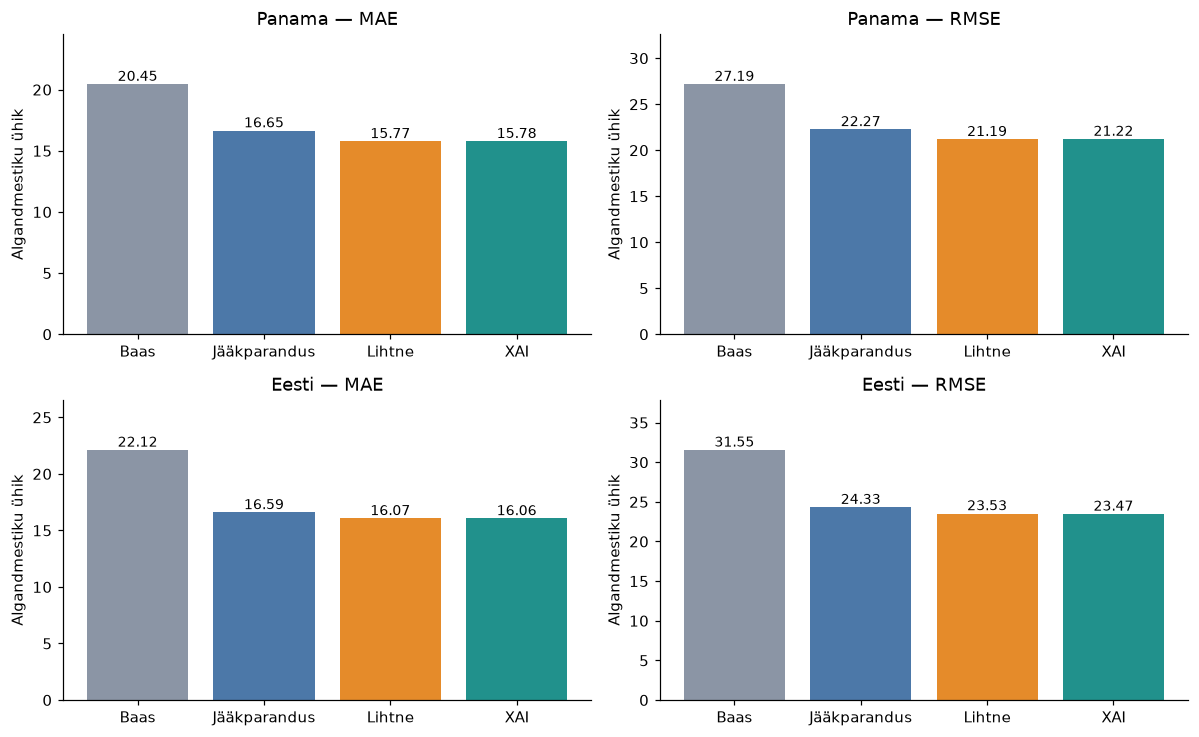

In [10]:
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(11, 3.4 * len(DATASETS)), squeeze=False)
for row, dataset in enumerate(DATASETS):
    values = overall[overall.dataset.eq(dataset)].set_index("method").loc[list(METHODS)]
    for col, metric in enumerate(("MAE", "RMSE")):
        ax = axes[row, col]
        bars = ax.bar([LABELS[m] for m in METHODS], values[metric],
                      color=[COLORS[m] for m in METHODS])
        ax.bar_label(bars, fmt="%.2f", fontsize=9)
        ax.set_title(f"{COUNTRIES[dataset]} — {metric}")
        ax.set_ylabel("Algandmestiku ühik")
        ax.margins(y=0.2)
fig.tight_layout()
plt.show()

## 7. Tulemus kuude lõikes
Kuine MAE näitab, millal parandajad aitavad või halvendavad. Nende tulemuste järgi seadeid ümber ei valita.

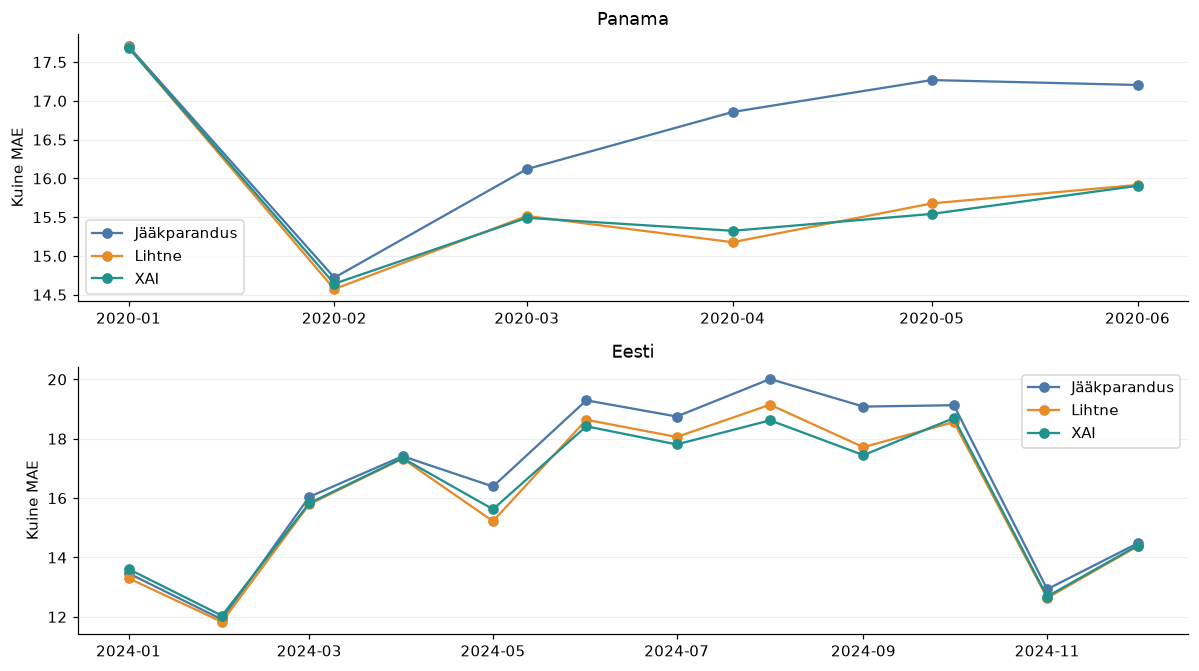

In [11]:
monthly = {}
fig, axes = plt.subplots(len(DATASETS), 1, figsize=(11, 3.1 * len(DATASETS)), squeeze=False)
for row, dataset in enumerate(DATASETS):
    frame = runs[dataset]["frame"]
    y = frame.target_next_hour.to_numpy()
    monthly[dataset] = pd.DataFrame({
        method: np.abs(runs[dataset]["forecasts"][method] - y)
        for method in METHODS if method != "base"
    }, index=pd.DatetimeIndex(frame.target_time)).resample("MS").mean()
    ax = axes[row, 0]
    for method in monthly[dataset]:
        ax.plot(monthly[dataset].index, monthly[dataset][method],
                marker="o", color=COLORS[method], label=LABELS[method])
    ax.set_title(COUNTRIES[dataset])
    ax.set_ylabel("Kuine MAE")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 8. Kiired koormusmuutused
Tõusu/languse piirid on leitud enne arendust. Tegelikku muutust kasutatakse ainult hindamistundide liigitamiseks. Tabeli n näitab alarühma suurust.

In [12]:
scope_view = metrics[
    metrics.scope.ne("overall") & metrics.method.isin(("residual", "hourly_bias", "credit_feedback"))
].assign(Andmestik=lambda x: x.dataset.map(COUNTRIES),
         Meetod=lambda x: x.method.map(LABELS))
display(scope_view[["Andmestik", "scope", "Meetod", "n", "MAE", "RMSE"]].rename(
    columns={"scope": "Olukord", "n": "Tunde"}
))

,Andmestik,Olukord,Meetod,Tunde,MAE,RMSE
7,Panama,rapid_increase,Jääkparandus,72,23.6682,33.2959
8,Panama,rapid_decrease,Jääkparandus,137,26.7330,34.5542
10,Panama,rapid_increase,Lihtne,72,23.1300,32.8417
11,Panama,rapid_decrease,Lihtne,137,26.7858,34.5369
22,Panama,rapid_increase,XAI,72,23.2331,32.5053
23,Panama,rapid_decrease,XAI,137,26.2101,34.2528
73,Eesti,rapid_increase,Jääkparandus,511,25.2181,35.7652
74,Eesti,rapid_decrease,Jääkparandus,383,40.1596,52.6240
76,Eesti,rapid_increase,Lihtne,511,23.8660,34.2452
77,Eesti,rapid_decrease,Lihtne,383,37.5440,49.6598


## 9. Millisest osast XAI-meetodi kasu tuleb?
Kontrollid kasutavad sama parandusmudelit ja XAI-meetodi seadeid: üks krediidikaal, komponentide koosmõjuta krediit või kellaajata mälu. Eraldi komponentide meetodil on lisaks oma arenduses valitud seaded. Need read aitavad eristada komponentide, krediidireegli ja kellaaja panust.

In [13]:
controls = ("residual", "scalar_adaptive", "standalone_feedback", "credit_feedback",
            "matched_scalar", "matched_standalone", "no_context")
display(overall[overall.method.isin(controls)].assign(
    Andmestik=lambda x: x.dataset.map(COUNTRIES), Meetod=lambda x: x.method.map(LABELS)
)[["Andmestik", "Meetod", "n", "MAE", "RMSE", "improvement_vs_residual_pct"]])

,Andmestik,Meetod,n,MAE,RMSE,improvement_vs_residual_pct
6,Panama,Jääkparandus,4273,16.6506,22.2651,0.0000
15,Panama,Üks adaptiivne kaal,4273,16.6227,22.2090,0.1678
18,Panama,Osad eraldi,4273,15.7654,21.2128,5.3165
21,Panama,XAI,4273,15.7765,21.2161,5.2498
24,Panama,Üks krediidikaal,4273,16.6476,22.2568,0.0178
27,Panama,Koosmõjuta,4273,15.7654,21.2128,5.3165
30,Panama,Kellaajata,4273,16.5531,22.1523,0.5856
72,Eesti,Jääkparandus,8654,16.5901,24.3281,0.0000
81,Eesti,Üks adaptiivne kaal,8654,16.5866,24.3286,0.0207
84,Eesti,Osad eraldi,8654,16.1378,23.5059,2.7259


## 10. Krediit, mälu ja parameetrite tundlikkus
MAE-krediit muudab ainult kasu mõõdikut; vananev mälu rõhutab värskemaid kogemusi. Üheksa akna/tugevuse kombinatsiooni on ette määratud tundlikkuskontrollid. Tabelist või soojuskaardilt uut lõppmeetodit ei valita.

In [14]:
robust_methods = ("residual", "credit_feedback", "mae_credit", "recency_credit")
display(overall[overall.method.isin(robust_methods)][
    ["dataset", "method", "n", "MAE", "RMSE", "improvement_vs_residual_pct",
     "harmful_rate_vs_base", "harmful_magnitude_vs_base"]
])

,dataset,method,n,MAE,RMSE,improvement_vs_residual_pct,harmful_rate_vs_base,harmful_magnitude_vs_base
6,panama,residual,4273,16.6506,22.2651,0.0000,0.3721,2.2034
21,panama,credit_feedback,4273,15.7765,21.2161,5.2498,0.3400,1.9728
33,panama,mae_credit,4273,15.8054,21.2752,5.0763,0.3436,1.9815
36,panama,recency_credit,4273,15.7790,21.2131,5.2347,0.3405,1.9801
72,estonia,residual,8654,16.5901,24.3281,0.0000,0.3470,2.5691
87,estonia,credit_feedback,8654,16.0589,23.4745,3.2017,0.3512,2.6904
99,estonia,mae_credit,8654,16.0683,23.5409,3.1448,0.3514,2.6645
102,estonia,recency_credit,8654,16.0569,23.4650,3.2140,0.3521,2.7008


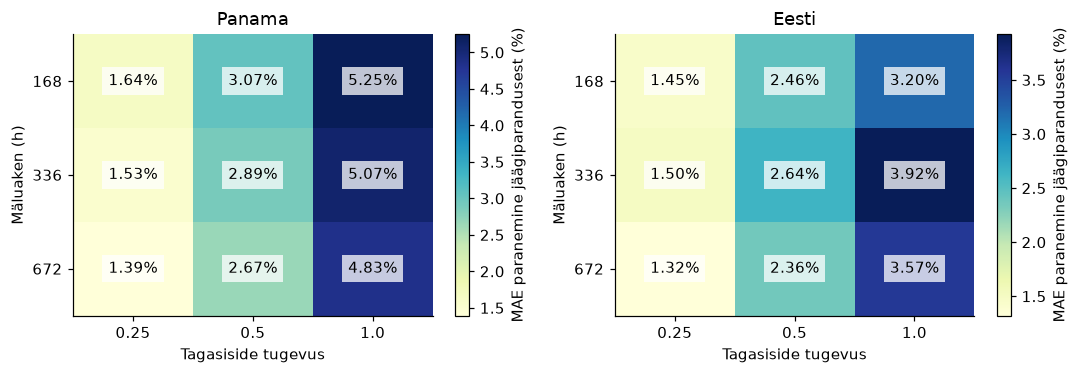

In [15]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(10, 3.5), squeeze=False)
for col, dataset in enumerate(DATASETS):
    values = overall[overall.dataset.eq(dataset) & overall.method.str.startswith("sensitivity_")].copy()
    values["window"] = values.method.str.extract(r"_w(\d+)", expand=False).astype(int)
    values["strength"] = values.method.str.extract(r"_s([\d.]+)", expand=False).astype(float)
    grid = values.pivot(index="window", columns="strength", values="improvement_vs_residual_pct")
    ax = axes[0, col]
    picture = ax.imshow(grid.to_numpy(), cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(len(grid.columns)), grid.columns)
    ax.set_yticks(range(len(grid.index)), grid.index)
    for row in range(len(grid.index)):
        for column in range(len(grid.columns)):
            ax.text(column, row, f"{grid.iloc[row, column]:.2f}%", ha="center", va="center",
                    bbox={"facecolor": "white", "alpha": 0.75, "edgecolor": "none"})
    ax.set(title=COUNTRIES[dataset], xlabel="Tagasiside tugevus", ylabel="Mäluaken (h)")
    fig.colorbar(picture, ax=ax, label="MAE paranemine jäägiparandusest (%)")
fig.tight_layout()
plt.show()

## 11. Lihtsa ja XAI-meetodi paarisvõrdlus
Vahe on **lihtsa absoluutviga − XAI absoluutviga**: negatiivne soosib lihtsat, positiivne XAI-meetodit. Ajaplokid arvestavad tundide sõltuvust; Bonferroni parandus katab mõlema riigi kolm olukorda.

Nulli sisaldav vahemik tähendab, et selget erinevust ei tuvastatud; see ei tõesta samaväärsust. Ajaloolisi arendusvalikuid see kontroll ei korrigeeri.

In [16]:
interval_rows = []
comparison_count = len(DATASETS) * 3
for dataset in DATASETS:
    run = runs[dataset]
    frame, forecasts = run["frame"], run["forecasts"]
    y = frame.target_next_hour.to_numpy()
    delta = abs(forecasts["hourly_bias"] - y) - abs(forecasts["credit_feedback"] - y)
    for scope, mask in scope_masks(frame, run["thresholds"]).items():
        if not mask.any():
            continue
        for block in cfg["evaluation"]["bootstrap_blocks_hours"]:
            interval_rows.append({
                "dataset": dataset, "scope": scope, "n": int(mask.sum()),
                **clock_loss_interval(
                    frame.target_time, delta, mask, block=block,
                    repeats=cfg["evaluation"]["bootstrap_repeats"],
                    seed=cfg["seed"], comparisons=comparison_count,
                ),
            })
intervals = pd.DataFrame(interval_rows)
primary_intervals = intervals[
    intervals.block_hours.eq(cfg["evaluation"]["primary_block_hours"])
].copy()
display(primary_intervals[[
    "dataset", "scope", "n", "difference", "adjusted_low", "adjusted_high"
]])

,dataset,scope,n,difference,adjusted_low,adjusted_high
1,panama,overall,4273,-0.0063,-0.1494,0.1298
3,panama,rapid_increase,72,-0.1032,-1.1115,0.7341
5,panama,rapid_decrease,137,0.5757,-0.1647,1.5909
7,estonia,overall,8654,0.0065,-0.1319,0.1576
9,estonia,rapid_increase,511,-0.0316,-0.6718,0.6133
11,estonia,rapid_decrease,383,0.6924,0.0565,1.2204


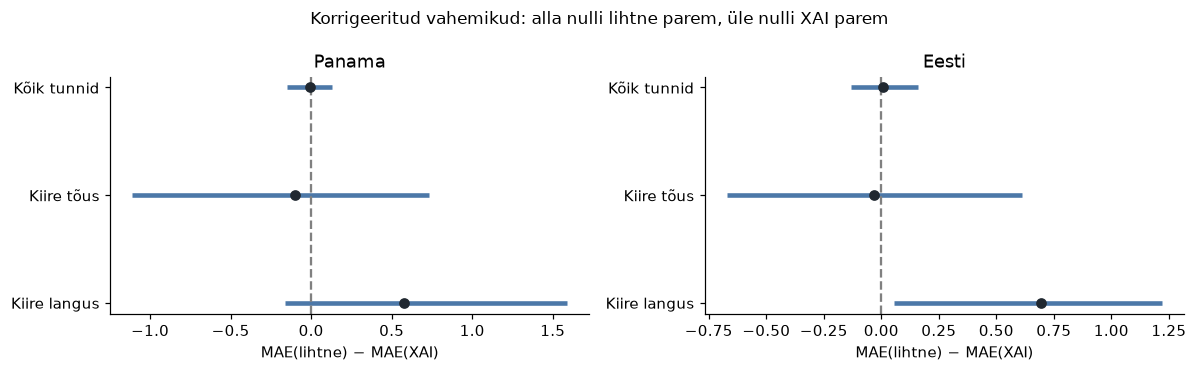

In [17]:
scope_labels = {"overall": "Kõik tunnid", "rapid_increase": "Kiire tõus",
                "rapid_decrease": "Kiire langus"}
fig, axes = plt.subplots(1, len(DATASETS), figsize=(11, 3.4), squeeze=False)
for col, dataset in enumerate(DATASETS):
    ax = axes[0, col]
    values = primary_intervals[primary_intervals.dataset.eq(dataset)]
    positions = np.arange(len(values))
    ax.hlines(positions, values.adjusted_low, values.adjusted_high, color="#4c78a8", linewidth=3)
    ax.scatter(values.difference, positions, color="#202830", zorder=3)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(positions, values.scope.map(scope_labels))
    ax.invert_yaxis()
    ax.set_title(COUNTRIES[dataset])
    ax.set_xlabel("MAE(lihtne) − MAE(XAI)")
fig.suptitle("Korrigeeritud vahemikud: alla nulli lihtne parem, üle nulli XAI parem", fontsize=11)
fig.tight_layout()
plt.show()

## 12. Kahjulikud parandused
Kahjulik tähendab baasprognoosist suuremat absoluutviga. Lisakahju keskmine arvestab kõiki hinnatud tunde. Väiksem MAE ei taga väiksemat kahjulikkust.

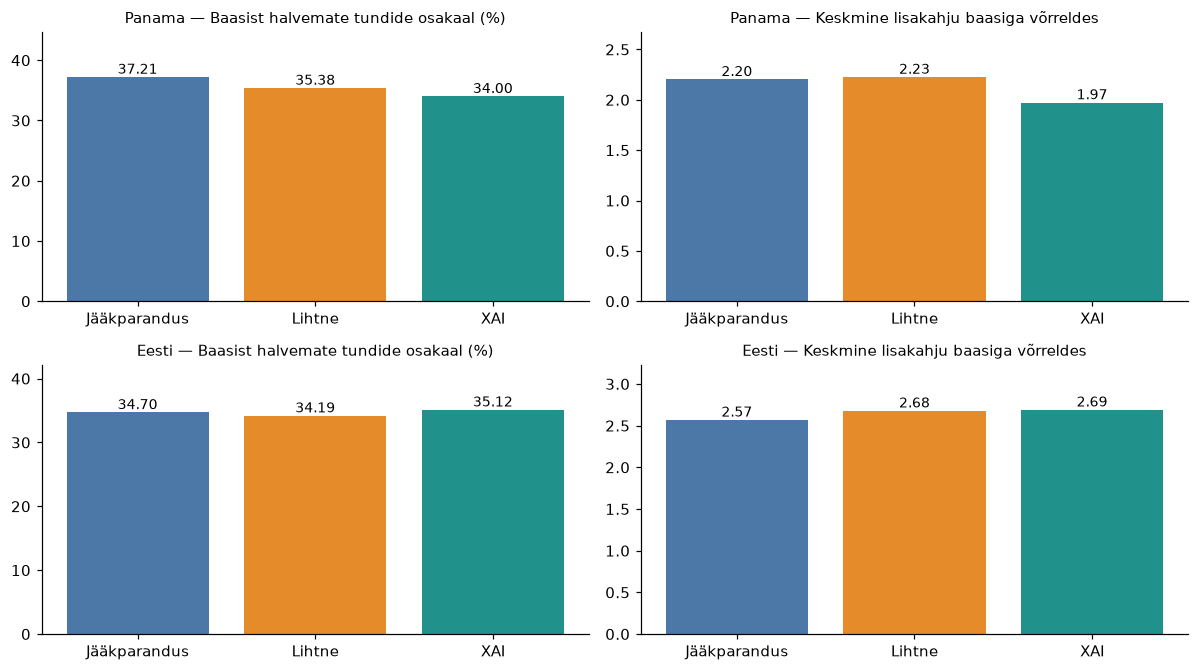

In [18]:
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(11, 3.1 * len(DATASETS)), squeeze=False)
corrections = [m for m in METHODS if m != "base"]
for row, dataset in enumerate(DATASETS):
    values = overall[overall.dataset.eq(dataset)].set_index("method").loc[corrections]
    for col, (metric, factor, title) in enumerate([
        ("harmful_rate_vs_base", 100, "Baasist halvemate tundide osakaal (%)"),
        ("harmful_magnitude_vs_base", 1, "Keskmine lisakahju baasiga võrreldes"),
    ]):
        ax = axes[row, col]
        bars = ax.bar([LABELS[m] for m in corrections], values[metric] * factor,
                      color=[COLORS[m] for m in corrections])
        ax.bar_label(bars, fmt="%.2f", fontsize=9)
        ax.set_title(f"{COUNTRIES[dataset]} — {title}", fontsize=10)
        ax.margins(y=0.2)
fig.tight_layout()
plt.show()

## 13. Prognoosid ajas
Näiteaken valitakse alguses määratud ajanihetega, mitte suurima võidu järgi. Paremal tähendab positiivne tulp XAI väiksemat absoluutviga, negatiivne lihtsa meetodi väiksemat viga.

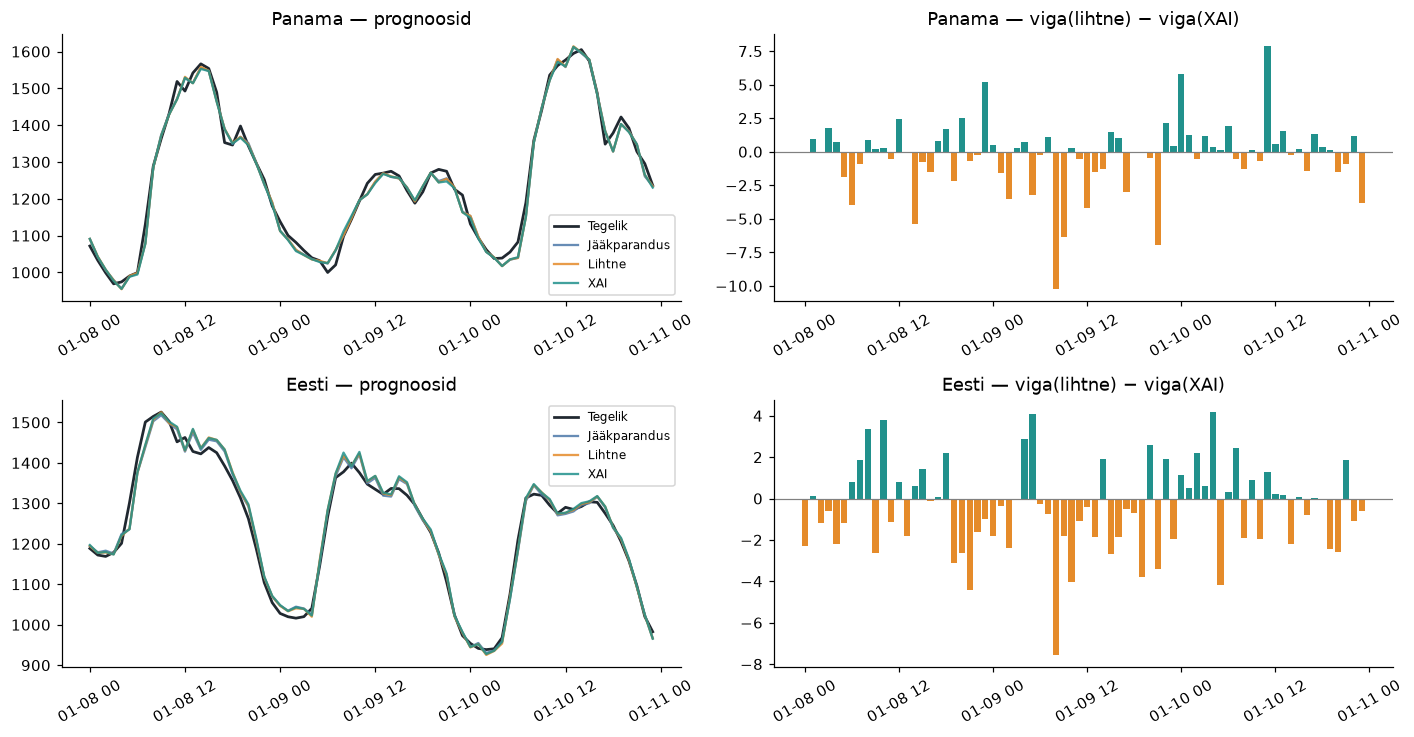

In [19]:
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(13, 3.4 * len(DATASETS)), squeeze=False)
for row, dataset in enumerate(DATASETS):
    frame, forecasts = runs[dataset]["frame"], runs[dataset]["forecasts"]
    start = frame.target_time.min() + pd.Timedelta(days=EXAMPLE_OFFSET_DAYS)
    mask = frame.target_time.ge(start) & frame.target_time.lt(start + pd.Timedelta(days=EXAMPLE_DAYS))
    times = frame.loc[mask, "target_time"]
    y = frame.target_next_hour.to_numpy()
    axes[row, 0].plot(times, y[mask], color="#202830", label="Tegelik", linewidth=1.8)
    for method in ("residual", "hourly_bias", "credit_feedback"):
        axes[row, 0].plot(times, forecasts[method][mask],
                          color=COLORS[method], label=LABELS[method], alpha=0.85)
    axes[row, 0].set_title(f"{COUNTRIES[dataset]} — prognoosid")
    axes[row, 0].legend(fontsize=8)
    delta = abs(forecasts["hourly_bias"] - y) - abs(forecasts["credit_feedback"] - y)
    axes[row, 1].bar(times, delta[mask], width=0.8 / 24,
                      color=np.where(delta[mask] >= 0, COLORS["credit_feedback"], COLORS["hourly_bias"]))
    axes[row, 1].axhline(0, color="gray", linewidth=0.8)
    axes[row, 1].set_title(f"{COUNTRIES[dataset]} — viga(lihtne) − viga(XAI)")
    for ax in axes[row]:
        ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

## 14. XAI-komponentide kaalud
Kaal 1 kasutab komponenti täielikult, 0 eemaldab selle. Keskmine kaal pole tunnuse tähtsus ega füüsikalise põhjuse hinnang; vastassuunalised osad võivad üksteist tasakaalustada.

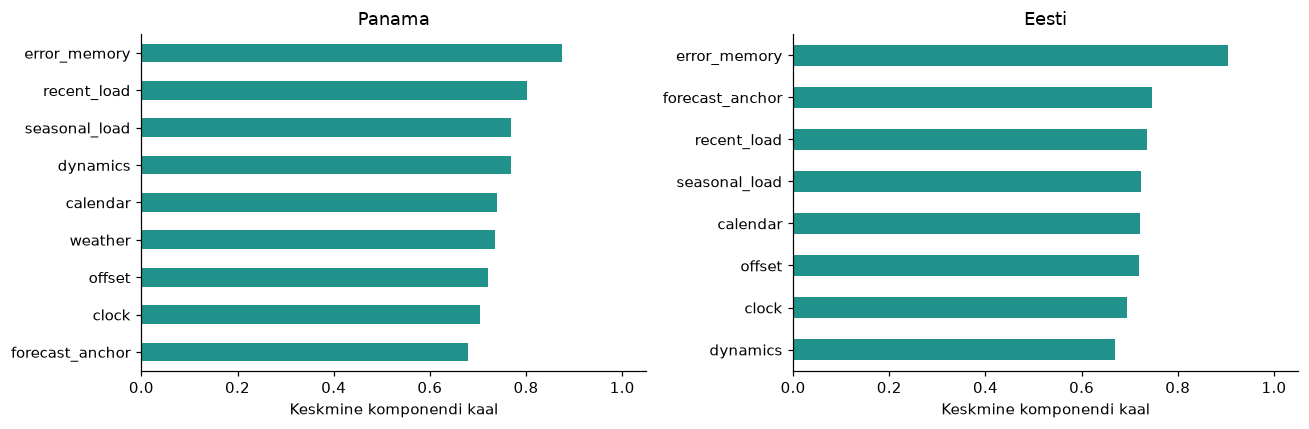

In [20]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(12, 4), squeeze=False)
for col, dataset in enumerate(DATASETS):
    average_weights = runs[dataset]["weights"].mean().sort_values()
    average_weights.plot.barh(ax=axes[0, col], color=COLORS["credit_feedback"])
    axes[0, col].set_xlim(0, 1.05)
    axes[0, col].set_title(COUNTRIES[dataset])
    axes[0, col].set_xlabel("Keskmine komponendi kaal")
fig.tight_layout()
plt.show()

## 15. Järeldus
Järeldus arvutatakse selle käivituse tulemustest. Üldine täpsus, rasked olukorrad ja kahjulikkus võivad anda eri vastuse. Üks konkurent ei tõesta meetodi üldist parimust.

Mällu jäävad `preliminary`, `development_results`, `selection`, `runs`, `metrics`, `monthly` ja `intervals`. Kõik tõlgendused ja tulemused jäävad siia notebooki.

Eeldame lõppenud tunni koormuse kohest saabumist. Panama ilmaandmed on viivitusega reanalüüs; tegelik avaldamisviivitus ning allika aja- ja ühikueeldused vajavad kinnitust. SHAP-osad ei tõenda põhjuslikkust.

In [21]:
for dataset in DATASETS:
    values = overall[overall.dataset.eq(dataset)].set_index("method")
    simple_mae = values.loc["hourly_bias", "MAE"]
    xai_mae = values.loc["credit_feedback", "MAE"]
    interval = primary_intervals[
        primary_intervals.dataset.eq(dataset) & primary_intervals.scope.eq("overall")
    ].iloc[0]
    if interval.adjusted_low > 0:
        conclusion = "XAI üldine MAE on selles võrdluses selgelt väiksem."
    elif interval.adjusted_high < 0:
        conclusion = "Lihtsa meetodi üldine MAE on selles võrdluses selgelt väiksem."
    else:
        conclusion = "Üldise MAE selget erinevust ei tuvastatud."
    print(f"{COUNTRIES[dataset]}: lihtne MAE {simple_mae:.4f}; XAI MAE {xai_mae:.4f}.")
    print(conclusion)
    print(f"Korrigeeritud vahemik lihtne − XAI: "
          f"[{interval.adjusted_low:.4f}, {interval.adjusted_high:.4f}]\n")

Panama: lihtne MAE 15.7702; XAI MAE 15.7765.
Üldise MAE selget erinevust ei tuvastatud.
Korrigeeritud vahemik lihtne − XAI: [-0.1494, 0.1298]

Eesti: lihtne MAE 16.0655; XAI MAE 16.0589.
Üldise MAE selget erinevust ei tuvastatud.
Korrigeeritud vahemik lihtne − XAI: [-0.1319, 0.1576]

